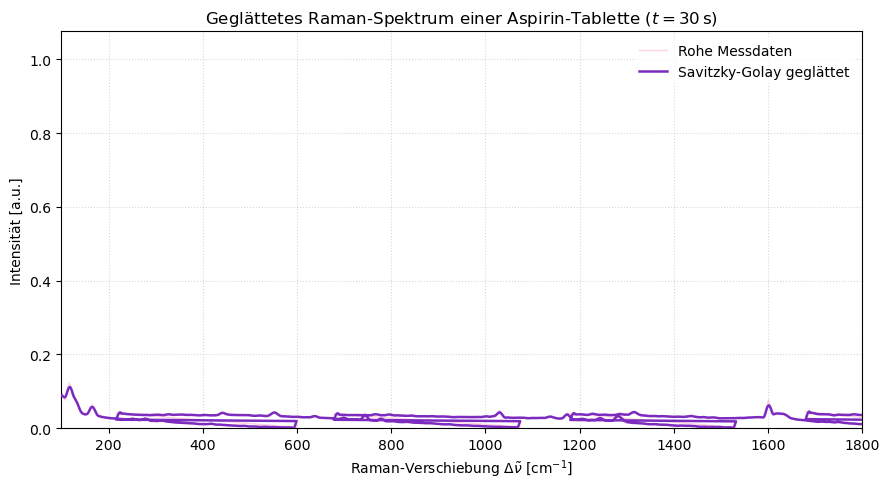

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import savgol_filter

# --- 1. DATEN EINLESEN UND KOMMAS ERSETZEN ---
comma_to_dot = lambda s: float(s.decode("utf-8").replace(",", "."))

data = np.loadtxt(
    "asperin_30s_wellenlänge(2Spalten).txt",
    delimiter="\t",
    converters={0: comma_to_dot, 1: comma_to_dot}
)

wavelength_nm = data[:, 0]
intensity_raw = data[:, 1]

# --- 2. TRANSFORMATION IN WELLENZAHLEN (cm^-1) ---
# FSU-Standard für HeNe-Laserwellenlänge
lambda_0 = 632.817 
wellenzahl_cm = (1.0 / lambda_0 - 1.0 / wavelength_nm) * 1e7

# Einfache Baseline-Korrektur (Minimum auf Null setzen)
intensity = intensity_raw - np.min(intensity_raw)

# --- 3. GEGLÄTTETE DATEN BERECHNEN (Savitzky-Golay) ---
# window_length: Fensterbreite (muss ungerade sein, z.B. 15 oder 21)
# polyorder: Polynomgrad (meistens 2 oder 3)
intensity_smoothed = savgol_filter(intensity, window_length=21, polyorder=3)

# --- 4. PROFESSIONELLER PLOT (Pink/Lila Farbschema) ---
plt.figure(figsize=(9, 5))

# Rohe Messdaten leicht transparent im Hintergrund
plt.plot(
    wellenzahl_cm, 
    intensity, 
    color="#FF70A6", 
    alpha=0.3, 
    linewidth=1.0, 
    label="Rohe Messdaten"
)

# Geglättete Kurve kräftig im Vordergrund
plt.plot(
    wellenzahl_cm, 
    intensity_smoothed, 
    color="#7B2CBF", 
    linewidth=1.8, 
    zorder=3, 
    label="Savitzky-Golay geglättet"
)

# Achsenbeschriftungen nach wissenschaftlichem FP-Standard
plt.title("Geglättetes Raman-Spektrum einer Aspirin-Tablette ($t = 30\\,\\text{s}$)")
plt.xlabel("Raman-Verschiebung $\\Delta\\tilde{\\nu}$ [$\\text{cm}^{-1}$]")
plt.ylabel("Intensität [a.u.]")

# Fokus auf den relevanten organischen Fingerabdruck-Bereich
plt.xlim(100, 1800) 
plt.ylim(0, np.max(intensity_smoothed) * 1.05)

plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

# Grafik anzeigen
plt.show()

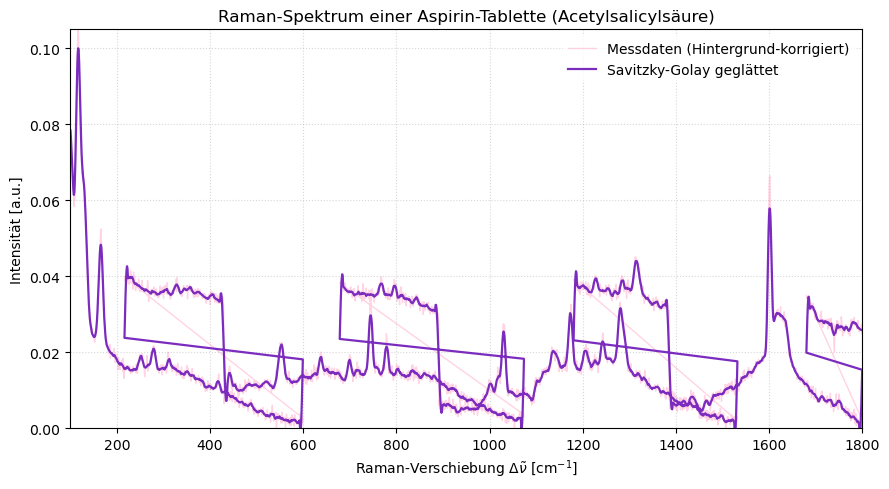

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import savgol_filter

# --- 1. DATEN EINLESEN ---
comma_to_dot = lambda s: float(s.decode("utf-8").replace(",", "."))
data = np.loadtxt(
    "asperin_30s_wellenlänge(2Spalten).txt",
    delimiter="\t",
    converters={0: comma_to_dot, 1: comma_to_dot}
)

wavelength_nm = data[:, 0]
intensity_raw = data[:, 1]

# --- 2. WELLENZAHL-TRANSFORMATION (cm^-1) ---
lambda_0 = 632.817 
wellenzahl_cm = (1.0 / lambda_0 - 1.0 / wavelength_nm) * 1e7

# --- 3. FILTERFLANKE ABSCHNEIDEN (Nur positive Raman-Verschiebungen) ---
# Wir betrachten nur den Bereich von 100 bis 1800 cm^-1, wo die Peaks liegen
valid_idx = (wellenzahl_cm >= 100) & (wellenzahl_cm <= 1800)
x = wellenzahl_cm[valid_idx]
y = intensity_raw[valid_idx]

# --- 4. BASELINE-KORREKTUR (Fluoreszenz/Hintergrund abziehen) ---
# Wir ziehen einen gleitenden Mindestwert ab, um die Peaks auf die Null-Linie zu bringen
window_size = 200
baseline = np.array([np.min(y[max(0, i-window_size):min(len(y), i+window_size)]) for i in range(len(y))])
y_corrected = y - baseline

# --- 5. SAVITZKY-GOLAY GLÄTTUNG ---
# Fensterbreite 15, Polynomgrad 3 für scharfe Peaks
y_smoothed = savgol_filter(y_corrected, window_length=15, polyorder=3)

# --- 6. PLOT IM LILA/PINK-FARBSCHEMA ---
plt.figure(figsize=(9, 5))

# Rohe korrigierte Daten im Hintergrund
plt.plot(x, y_corrected, color="#FF70A6", alpha=0.3, linewidth=1.0, label="Messdaten (Hintergrund-korrigiert)")

# Sauber geglättete Kurve im Vordergrund
plt.plot(x, y_smoothed, color="#7B2CBF", linewidth=1.6, label="Savitzky-Golay geglättet")

# Achsenbeschriftungen nach FP-Standard
plt.title("Raman-Spektrum einer Aspirin-Tablette (Acetylsalicylsäure)")
plt.xlabel("Raman-Verschiebung $\\Delta\\tilde{\\nu}$ [$\\text{cm}^{-1}$]")
plt.ylabel("Intensität [a.u.]")

plt.xlim(100, 1800)
plt.ylim(0, np.max(y_smoothed) * 1.05)

plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

plt.show()

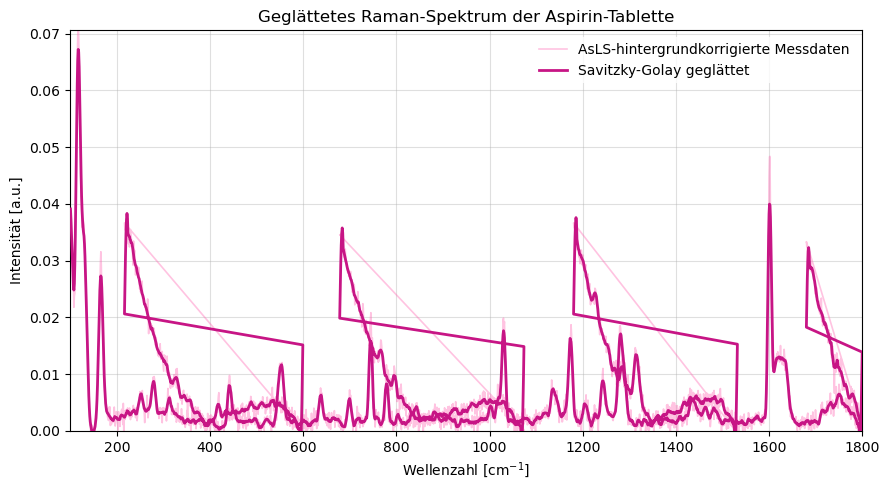

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.sparse import diags, eye
from scipy.sparse.linalg import spsolve

# --- 1. KORRIGIERTER BASELINE-ALGORITHMUS (AsLS) ---
def als_baseline(y, lam, p, niter=10):
    """
    Asymmetric Least Squares Smoothing nach Eilers (2005).
    Erzeugt die Matrizen dynamisch passend zur Dimension von y.
    """
    L = len(y)
    # Erzeuge die Matrix D (zweite Ableitung) passend zur aktuellen Länge L
    D = diags([1, -2, 1], [0, 1, 2], shape=(L - 2, L))
    w = np.ones(L)
    
    # Berechne lam * D^T * D einmal vor der Schleife (spart Rechenzeit)
    A = lam * D.transpose().dot(D)
    
    for i in range(niter):
        # W als sparse Diagonalkmatrix
        W = diags([w], [0], shape=(L, L))
        # Da W und A beide (L, L) sind, passt die Addition jetzt perfekt
        Z = W + A
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)
    return z

# --- 2. DATEN EINLESEN AND TRANSFORMIEREN ---
comma_to_dot = lambda s: float(s.decode("utf-8").replace(",", "."))
data = np.loadtxt(
    "asperin_30s_wellenlänge(2Spalten).txt",
    delimiter="\t",
    converters={0: comma_to_dot, 1: comma_to_dot}
)

wavelength_nm = data[:, 0]
intensity_raw = data[:, 1]

# Transformation in Raman-Verschiebung (cm^-1)
lambda_0 = 632.817
wellenzahl_cm = (1.0 / lambda_0 - 1.0 / wavelength_nm) * 1e7

# --- 3. DATEN BESCHNEIDEN (Fokus auf echten Fingerabdruck) ---
valid_idx = (wellenzahl_cm >= 100) & (wellenzahl_cm <= 1800)
x = wellenzahl_cm[valid_idx]
y = intensity_raw[valid_idx]

# --- 4. BASELINE KORREKTUR & GLÄTTUNG ---
# lam=1e4 und p=0.001 eignen sich exzellent für den Fluoreszenzuntergrund von Aspirin
baseline = als_baseline(y, lam=1e4, p=0.001)
y_corrected = y - baseline

# Savitzky-Golay-Glättung im Stil eures Notebooks
y_smoothed = savgol_filter(y_corrected, window_length=15, polyorder=3)

# --- 5. VISUALISIERUNG NACH LABMATE-STIL ---
plt.figure(figsize=(9, 5))

plt.plot(
    x, y_corrected, 
    color="hotpink", alpha=0.4, linewidth=1.2, 
    label="AsLS-hintergrundkorrigierte Messdaten"
)
plt.plot(
    x, y_smoothed, 
    color="mediumvioletred", linewidth=2.0, zorder=3, 
    label="Savitzky-Golay geglättet"
)

plt.title("Geglättetes Raman-Spektrum der Aspirin-Tablette")
plt.xlabel("Wellenzahl [cm$^{-1}$]")
plt.ylabel("Intensität [a.u.]")
plt.xlim(100, 1800)
plt.ylim(0, np.max(y_smoothed) * 1.05)

plt.grid(True, alpha=0.4)
plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

plt.show()

Peak bei: 633.115 nm, Intensität (norm.) = 1.000


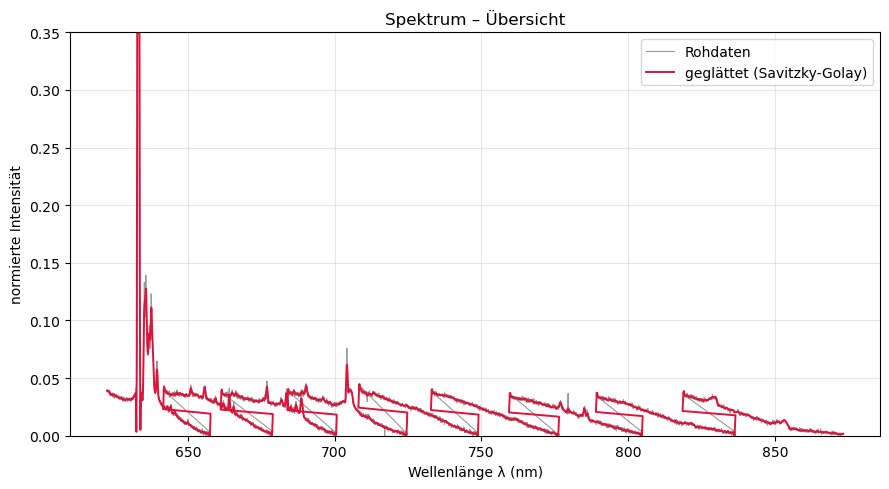

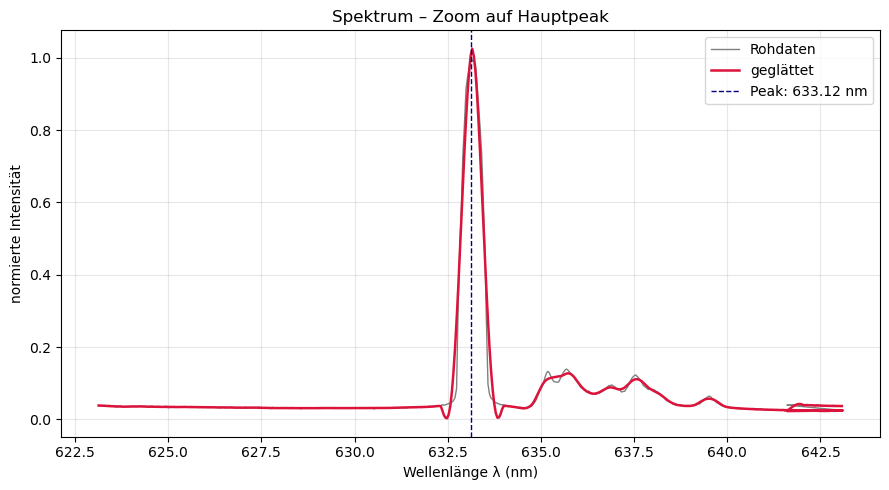

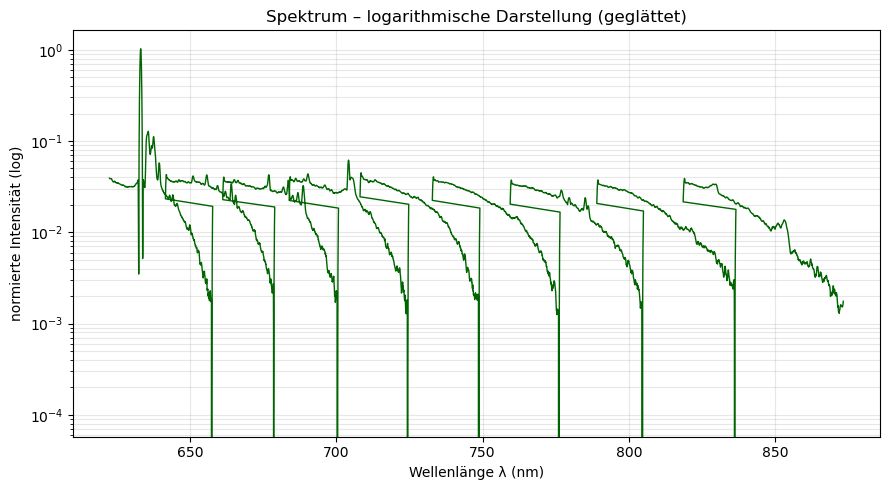

Plots gespeichert: spektrum_uebersicht.png, spektrum_zoom_peak.png, spektrum_log.png


In [4]:
"""
Plot-Skript für Spektroskopie-Daten (Wellenlänge / Intensität, 2 Spalten, Komma als Dezimaltrenner)
Erstellt:
  1) Übersichtsplot über den gesamten Wellenlängenbereich
  2) Zoom-Plot auf den Hauptpeak (z.B. HeNe-Linie bei 632.8 nm)
  3) Geglättete Kurve (Savitzky-Golay) zum Vergleich
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

wellenlaenge, intensitaet = [], []
with open("asperin_30s_wellenlänge(2Spalten).txt", "r", encoding="utf-8") as f:
    for zeile in f:
        zeile = zeile.strip()
        if not zeile:
            continue
        teile = zeile.split("\t") if "\t" in zeile else zeile.split()
        x, y = teile[0].replace(",", "."), teile[1].replace(",", ".")
        wellenlaenge.append(float(x))
        intensitaet.append(float(y))

wellenlaenge = np.array(wellenlaenge)
intensitaet = np.array(intensitaet)

# ---------- Glättung (Savitzky-Golay) ----------
fenster = 21      # muss ungerade sein, ggf. anpassen
ordnung = 3
intensitaet_glatt = savgol_filter(intensitaet, fenster, ordnung)

# Index des Maximums (Peak) finden, um Zoom-Bereich zu bestimmen
peak_idx = np.argmax(intensitaet)
peak_x = wellenlaenge[peak_idx]
print(f"Peak bei: {peak_x:.3f} nm, Intensität (norm.) = {intensitaet[peak_idx]:.3f}")

# ---------- Plot 1: Übersicht über gesamten Bereich ----------
fig1, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(wellenlaenge, intensitaet, lw=0.8, color="0.6", label="Rohdaten")
ax1.plot(wellenlaenge, intensitaet_glatt, lw=1.4, color="crimson", label="geglättet (Savitzky-Golay)")
ax1.set_xlabel("Wellenlänge λ (nm)")
ax1.set_ylabel("normierte Intensität")
ax1.set_ylim(0, 0.35)
ax1.set_title("Spektrum – Übersicht")
ax1.legend()
ax1.grid(alpha=0.3)
fig1.tight_layout()
fig1.savefig("spektrum_uebersicht.png", dpi=200)

# ---------- Plot 2: Zoom auf den Hauptpeak ----------
breite = 10  # nm links/rechts vom Peak
maske = (wellenlaenge > peak_x - breite) & (wellenlaenge < peak_x + breite)

fig2, ax2 = plt.subplots(figsize=(9, 5))
ax2.plot(wellenlaenge[maske], intensitaet[maske], lw=1.0, color="0.5", label="Rohdaten")
ax2.plot(wellenlaenge[maske], intensitaet_glatt[maske], lw=1.8, color="crimson", label="geglättet")
ax2.axvline(peak_x, color="navy", ls="--", lw=1, label=f"Peak: {peak_x:.2f} nm")
ax2.set_xlabel("Wellenlänge λ (nm)")
ax2.set_ylabel("normierte Intensität")
ax2.set_title("Spektrum – Zoom auf Hauptpeak")
ax2.legend()
ax2.grid(alpha=0.3)
fig2.tight_layout()
fig2.savefig("spektrum_zoom_peak.png", dpi=200)

# ---------- Plot 3: log-Skala (zeigt auch schwache Nebenpeaks) ----------
fig3, ax3 = plt.subplots(figsize=(9, 5))
ax3.semilogy(wellenlaenge, intensitaet_glatt + 1e-4, lw=1.0, color="darkgreen")
ax3.set_xlabel("Wellenlänge λ (nm)")
ax3.set_ylabel("normierte Intensität (log)")
ax3.set_title("Spektrum – logarithmische Darstellung (geglättet)")
ax3.grid(alpha=0.3, which="both")
fig3.tight_layout()
fig3.savefig("spektrum_log.png", dpi=200)

plt.show()
print("Plots gespeichert: spektrum_uebersicht.png, spektrum_zoom_peak.png, spektrum_log.png")

Hauptpeak bei: -2.74 cm^-1, Intensität (norm.) = 1.000


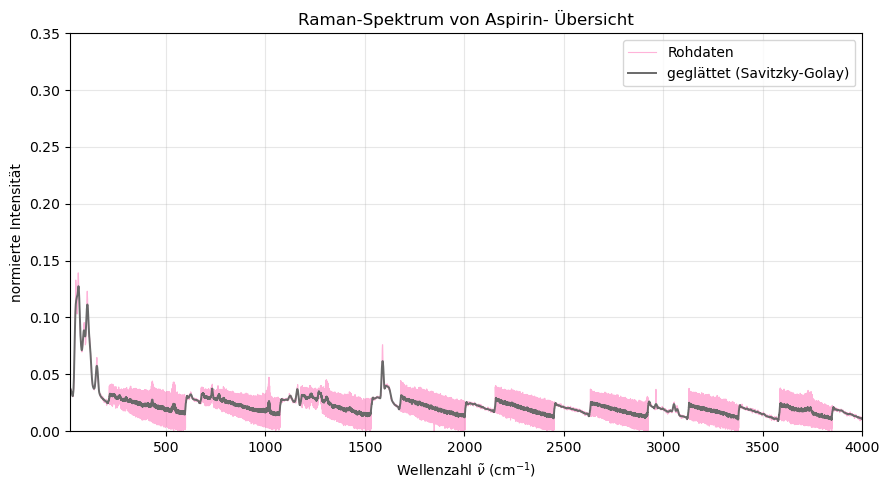

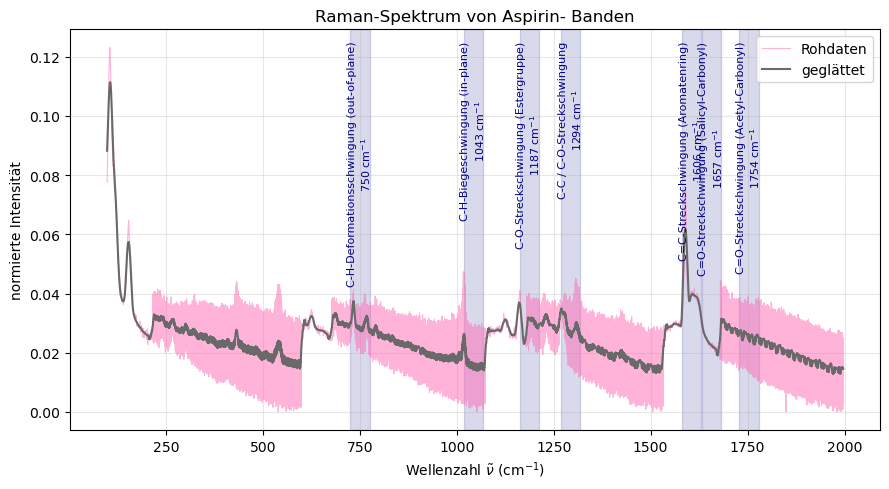

In [10]:
"""
Plot-Skript für Spektroskopie-Daten (Wellenzahl / Intensität, 2 Spalten, Komma als Dezimaltrenner)
Erstellt:
  1) Übersichtsplot über den gesamten Wellenzahlbereich
  2) Zoom-Plot auf den Fingerprintbereich (Raman-Banden) mit beschrifteten charakteristischen Peaks
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

wellenzahl, intensitaet = [], []
with open("asperin_30s(2Spalten).txt", "r", encoding="utf-8") as f:
    for zeile in f:
        zeile = zeile.strip()
        if not zeile:
            continue
        teile = zeile.split("\t") if "\t" in zeile else zeile.split()
        x, y = teile[0].replace(",", "."), teile[1].replace(",", ".")
        wellenzahl.append(float(x))
        intensitaet.append(float(y))

wellenzahl = np.array(wellenzahl)
intensitaet = np.array(intensitaet)

# Die Rohdaten bestehen aus mehreren zusammengesetzten Gitterfenstern mit Überlappung
# (an einigen Stellen springt die Wellenzahl zurück). Für eine glatte Darstellung
# werden die Punkte nach Wellenzahl sortiert.
sortier_idx = np.argsort(wellenzahl)
wellenzahl = wellenzahl[sortier_idx]
intensitaet = intensitaet[sortier_idx]

# ---------- Glättung (Savitzky-Golay) ----------
fenster = 21      # muss ungerade sein, ggf. anpassen
ordnung = 3
intensitaet_glatt = savgol_filter(intensitaet, fenster, ordnung)

# Index des Maximums (Hauptpeak) finden
peak_idx = np.argmax(intensitaet)
peak_x = wellenzahl[peak_idx]
print(f"Hauptpeak bei: {peak_x:.2f} cm^-1, Intensität (norm.) = {intensitaet[peak_idx]:.3f}")

# ---------- Plot 1: Übersicht über gesamten Bereich ----------
fig1, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(wellenzahl, intensitaet, lw=0.8, color="hotpink", label="Rohdaten", alpha=0.5)
ax1.plot(wellenzahl, intensitaet_glatt, lw=1.4, color="dimgrey", label="geglättet (Savitzky-Golay)")
ax1.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax1.set_ylabel("normierte Intensität")
ax1.set_title("Raman-Spektrum von Aspirin- Übersicht")
ax1.legend()
ax1.set_xlim(20,4000)
ax1.set_ylim(0, 0.35)
ax1.grid(alpha=0.3)
fig1.tight_layout()
#fig1.savefig("spektrum_uebersicht_wellenzahl.png", dpi=200)

# ---------- Plot 2: Zoom auf den Fingerprint-/Ramanbereich (ohne den dominanten Peak) ----------
# zusammenhängender Bereich ab ~100 cm^-1 hinter dem Hauptpeak bis 2000 cm^-1
fingerprint_maske = (wellenzahl > peak_x + 100) & (wellenzahl < peak_x + 2000)

fig2, ax2 = plt.subplots(figsize=(9, 5))
ax2.plot(wellenzahl[fingerprint_maske], intensitaet[fingerprint_maske], lw=0.8, color="hotpink", label="Rohdaten", alpha=0.5)
ax2.plot(wellenzahl[fingerprint_maske], intensitaet_glatt[fingerprint_maske], lw=1.5, color="dimgrey", label="geglättet")

# ---------- Charakteristische Aspirin-Banden beschriften (axvspan + Text) ----------
# --- Exakte Peak-Werte aus E.L. Crowell et al. (Table 1, unbehandelte ASA Form I) ---
charakteristische_peaks = [
    (750,  "C-H-Deformationsschwingung (out-of-plane)"),
    (1043, "C-H-Biegeschwingung (in-plane)"),
    (1187, "C-O-Streckschwingung (Estergruppe)"),
    (1294, "C-C / C-O-Streckschwingung"),
    (1606, "C=C-Streckschwingung (Aromatenring)"),
    (1657, "C=O-Streckschwingung (Salicyl-Carbonyl)"),
    (1754, "C=O-Streckschwingung (Acetyl-Carbonyl)")
]

breite = 25  # halbe Breite des markierten Bereichs in cm^-1
y_max = ax2.get_ylim()[1]

for position, beschriftung in charakteristische_peaks:
    ax2.axvspan(position - breite, position + breite, color="navy", alpha=0.15)
    ax2.text(position, y_max * 0.97, f"{beschriftung}\n{position} cm$^{{-1}}$",
              rotation=90, ha="center", va="top", fontsize=8, color="navy")

ax2.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax2.set_ylabel("normierte Intensität")
ax2.set_title("Raman-Spektrum von Aspirin- Banden")
ax2.legend(loc="upper right")
ax2.grid(alpha=0.3)
fig2.tight_layout()
#fig2.savefig("spektrum_fingerprint_wellenzahl.png", dpi=200)

plt.show()


Hauptpeak bei: 633.12 cm^-1


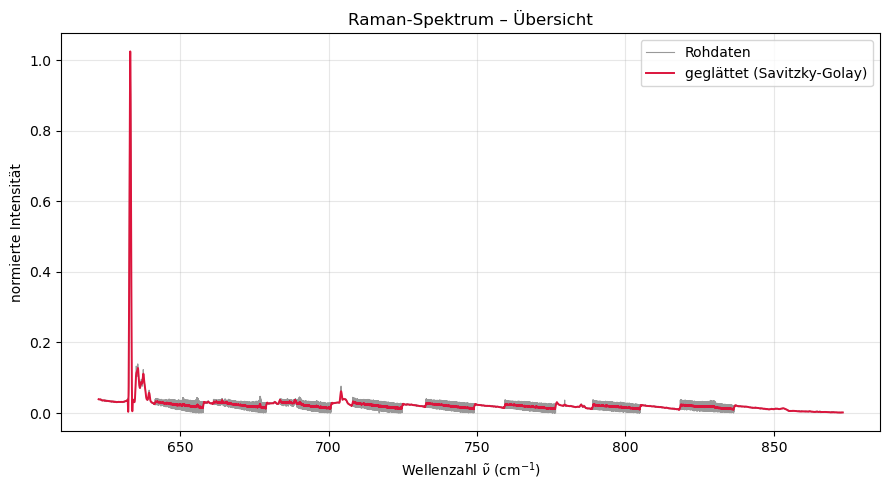

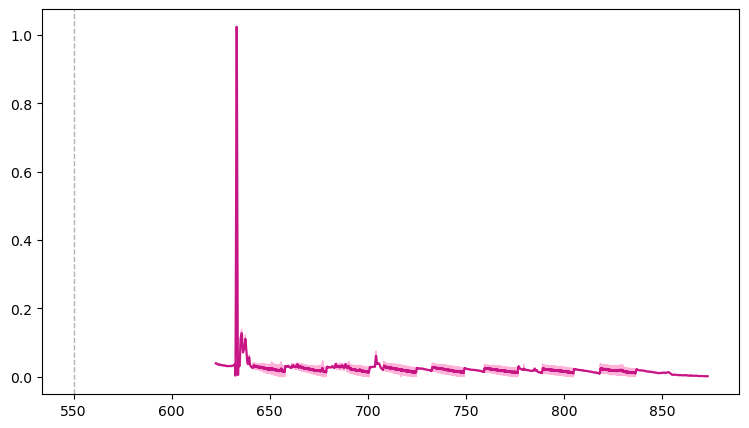

In [ ]:
"""
Plot-Skript für Spektroskopie-Daten (Wellenzahl / Intensität, 2 Spalten, Komma als Dezimaltrenner)
Erstellt:
  1) Übersichtsplot über den gesamten Wellenzahlbereich
  2) Zoom-Plot auf den Fingerprint-Bereich inklusive Einzeichnung der charakteristischen Banden
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

wellenzahl, intensitaet = [], []
with open("asperin_30s_wellenlänge(2Spalten).txt", "r", encoding="utf-8") as f:
    for zeile in f:
        zeile = zeile.strip()
        if not zeile:
            continue
        teile = zeile.split("\t") if "\t" in zeile else zeile.split()
        x, y = teile[0].replace(",", "."), teile[1].replace(",", ".")
        wellenzahl.append(float(x))
        intensitaet.append(float(y))

wellenzahl = np.array(wellenzahl)
intensitaet = np.array(intensitaet)

# Sortierung nach Wellenzahl
sortier_idx = np.argsort(wellenzahl)
wellenzahl = wellenzahl[sortier_idx]
intensitaet = intensitaet[sortier_idx]

# ---------- Glättung (Savitzky-Golay) ----------
fenster = 21      # muss ungerade sein
ordnung = 3
intensitaet_glatt = savgol_filter(intensitaet, fenster, ordnung)

# Index des Maximums finden
peak_idx = np.argmax(intensitaet)
peak_x = wellenzahl[peak_idx]
print(f"Hauptpeak bei: {peak_x:.2f} cm^-1")

# ---------- Plot 1: Übersicht über gesamten Bereich ----------
fig1, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(wellenzahl, intensitaet, lw=0.8, color="0.6", label="Rohdaten")
ax1.plot(wellenzahl, intensitaet_glatt, lw=1.4, color="crimson", label="geglättet (Savitzky-Golay)")
ax1.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax1.set_ylabel("normierte Intensität")
ax1.set_title("Raman-Spektrum – Übersicht")
ax1.legend()
ax1.grid(alpha=0.3)
fig1.tight_layout()
fig1.savefig("spektrum_uebersicht_wellenzahl.png", dpi=200)

# ---------- Plot 2: Zoom auf den Fingerprintbereich mit Charakteristika ----------
# Bereich ab 100 cm^-1 bis 1800 cm^-1 für organische Banden
fingerprint_maske = (wellenzahl > 100) & (wellenzahl < 1800)

fig2, ax2 = plt.subplots(figsize=(9, 5))
ax2.plot(wellenzahl[fingerprint_maske], intensitaet[fingerprint_maske], lw=0.8, color="hotpink", alpha=0.5, label="Rohdaten")
ax2.plot(wellenzahl[fingerprint_maske], intensitaet_glatt[fingerprint_maske], lw=1.6, color="mediumvioletred", label="geglättet")

# --- EINZEICHNUNG DER CHARAKTERISTISCHEN ASPIRIN-BANDEN ---
# Definition der charakteristischen Wellenzahlen und deren Zuordnung für das Protokoll
charakteristische_banden = {
    550: "Ringdeform.",
    640: "Ringdeform.",
    1045: "C-H Biege.",
    1606: "C=C (Aromat)",
    1655: "C=O Ester",
    1760: "C=O Carboxyl"
}

# Schleife zum automatischen Zeichnen der vertikalen Linien
for wz, label in charakteristische_banden.items():
    # Zeichne gestrichelte Linie
    ax2.axvline(x=wz, color="gray", linestyle="--", alpha=0.6, lw=1.0)
    # Beschriftung oben im Plot platzieren
    ax2.text(wz, ax2.get_ylim()[1] * 0.9, f" {wz} cm$^{{-1}}$\n ({label})", 
             rotation=90, fontsize=8, color="darkslate gray", va="top", ha="left")

ax2.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax2.set_ylabel("normierte Intensität")
ax2.set_title("Raman-Spektrum Aspirin – Charakteristische Banden")
ax2.legend(loc="upper right")
ax2.grid(alpha=0.3)
ax2.set_xlim(100, 1850)

fig2.tight_layout()
fig2.savefig("spektrum_fingerprint_wellenzahl.png", dpi=200)

plt.show()
print("Plots erfolgreich gespeichert!")